TensorFlow: 2.14.1
Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 64, 64, 4)]       0         
                                                                 
 conv2d (Conv2D)             (None, 64, 64, 32)        1152      
                                                                 
 batch_normalization (Batch  (None, 64, 64, 32)        128       
 Normalization)                                                  
                                                                 
 activation (Activation)     (None, 64, 64, 32)        0         
                                                                 
 conv2d_1 (Conv2D)           (None, 64, 64, 32)        9216      
                                                                 
 batch_normalization_1 (Bat  (None, 64, 64, 32)        128       
 chNormalization)                         

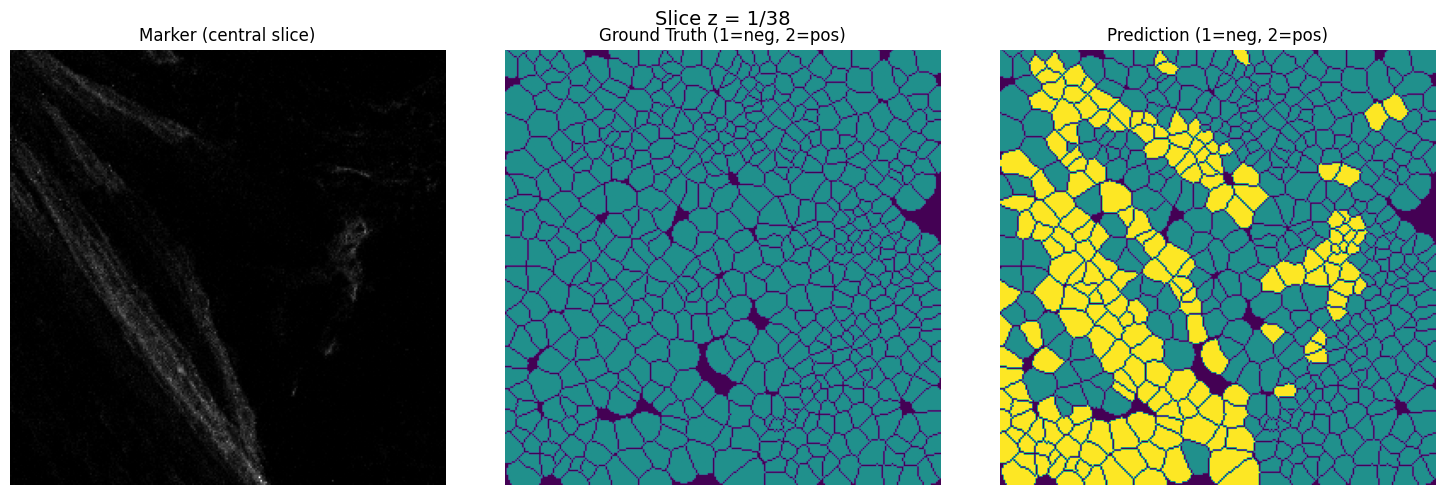


Processing slice 2/38
Cells in slice: 573


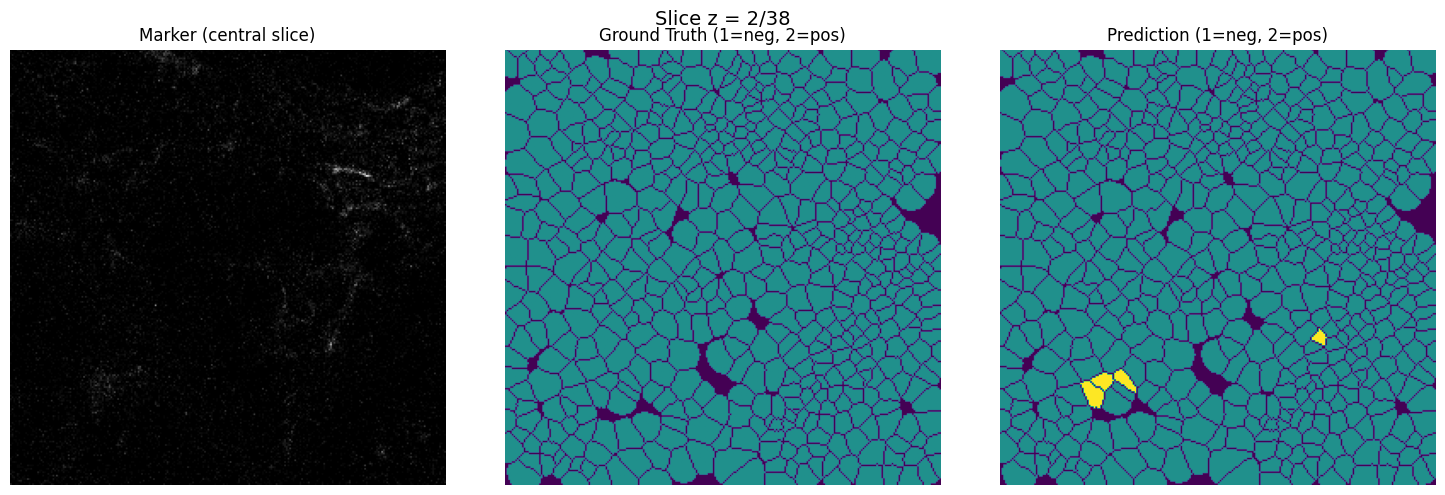


Processing slice 3/38
Cells in slice: 573


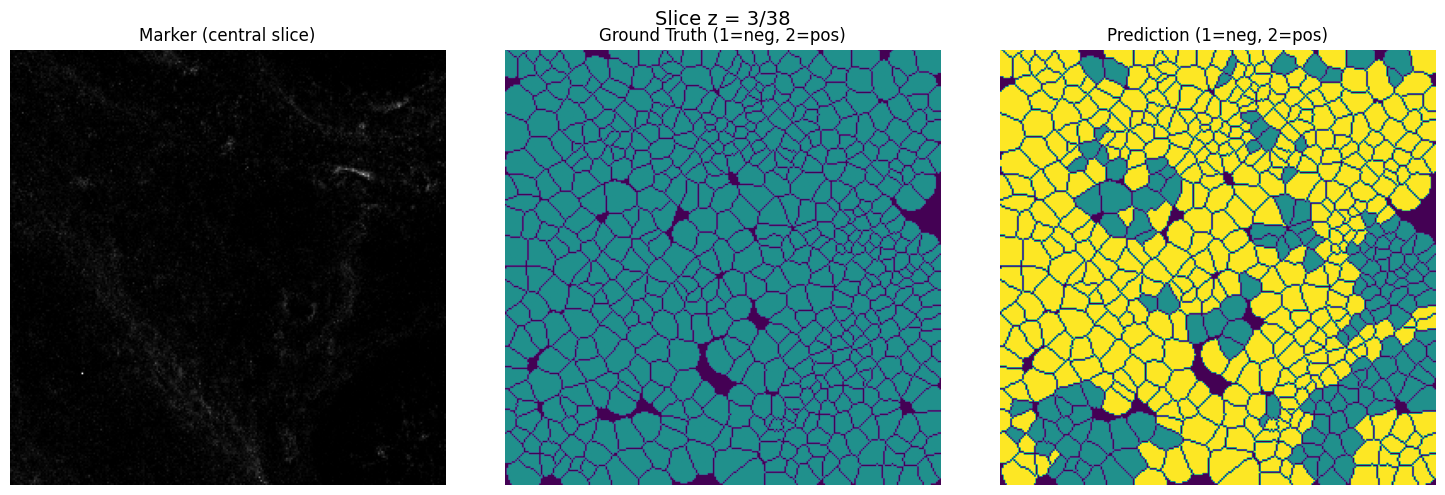


Processing slice 4/38
Cells in slice: 573


KeyboardInterrupt: 

In [4]:
import numpy as np
import nibabel as nib
import tensorflow as tf
from scipy.ndimage import label as cc_label
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)

# ------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------
# markers_nii_path  = "EMMA1.nii"
# mask_nii_path     = "EMMA1_inference_corrected.nii"
# out_path          = "EMMA1_reinference_test.nii"

# markers_nii_path  = "X02_a0_full.nii.gz"
# mask_nii_path     = "X02_a0_full_mask_modified.nii.gz"

markers_nii_path  = "EMMA2.nii"
mask_nii_path     = "EMMA2_mask.nii"
out_path          = "EMMA2_inference.nii"

model_path        = "checkpoints_set2/marker_cnn_epoch_100.h5"

PATCH_SIZE = 64
THRESHOLD  = 0.5
CHUNK_SIZE = 1024

# ------------------------------------------------------------
# LOAD MODEL
# ------------------------------------------------------------
model = tf.keras.models.load_model(model_path)
model.summary()

# ------------------------------------------------------------
# LOAD DATA
# ------------------------------------------------------------
markers_nii = nib.load(markers_nii_path)
mask_nii    = nib.load(mask_nii_path)

markers_nii = nib.as_closest_canonical(markers_nii)
mask_nii    = nib.as_closest_canonical(mask_nii)

markers = markers_nii.get_fdata().astype(np.float32)
mask    = mask_nii.get_fdata().astype(np.int16)

if markers.shape != mask.shape:
    raise ValueError("Shape mismatch between marker and mask volumes.")

H, W, Z = markers.shape
print("Volume shape:", markers.shape)

inference_mask = np.zeros_like(mask, dtype=np.int16)

# ------------------------------------------------------------
# HELPERS (MATCH TRAINING GENERATOR)
# ------------------------------------------------------------
def get_neighbor_slices(img_data, z):
    Z = img_data.shape[2]
    if z == 0:
        z_prev = z
        z_next = z + 1
    elif z == Z - 1:
        z_prev = z - 1
        z_next = z
    else:
        z_prev = z - 1
        z_next = z + 1

    return (
        img_data[:, :, z_prev],
        img_data[:, :, z],
        img_data[:, :, z_next],
    )


def center_crop_on_mask(img, mask, crop_size=64):
    """
    Identical behavior to extract_cell_patch_and_bbox,
    but takes a binary mask instead of a labeled slice.
    """

    H, W = img.shape[:2]
    ys, xs = np.where(mask > 0.5)

    if ys.size == 0:
        return None, None

    # SAME center computation (no rounding)
    cy = int(np.mean(ys))
    cx = int(np.mean(xs))

    half = crop_size // 2

    # SAME boundary logic
    y0 = max(0, cy - half)
    x0 = max(0, cx - half)
    y1 = min(H, y0 + crop_size)
    x1 = min(W, x0 + crop_size)

    if y1 - y0 < crop_size:
        y0 = max(0, y1 - crop_size)
    if x1 - x0 < crop_size:
        x0 = max(0, x1 - crop_size)

    img_crop = img[y0:y1, x0:x1]
    mask_crop = mask[y0:y1, x0:x1]

    return img_crop, mask_crop


def flush_chunk(patches, cell_ids, labeled_slice, z_index):
    if not patches:
        return

    X = np.stack(patches, axis=0).astype(np.float32)
    probs = model.predict(X, batch_size=512, verbose=0).reshape(-1)

    slice_out = inference_mask[:, :, z_index]  # important: write into view

    for cid, p in zip(cell_ids, probs):
        label_val = 2 if p >= THRESHOLD else 1
        slice_out[labeled_slice == cid] = label_val

    patches.clear()
    cell_ids.clear()

# ------------------------------------------------------------
# INFERENCE LOOP
# ------------------------------------------------------------
for z in range(Z):

    print(f"\nProcessing slice {z+1}/{Z}")

    img_prev, img_curr, img_next = get_neighbor_slices(markers, z)
    mask_slice = mask[:, :, z]

    # EXACTLY as in training generation
    cell_region = mask_slice > 0
    labeled, num_components = cc_label(cell_region)

    print("Cells in slice:", num_components)

    if num_components == 0:
        continue

    patches = []
    cell_ids = []

    for comp_id in range(1, num_components + 1):

        # Create binary mask for this cell
        cell_mask_full = (labeled == comp_id).astype(np.float32)

        # Center crop using identical logic to training
        img_curr_patch, cell_patch = center_crop_on_mask(
            img_curr,
            cell_mask_full,
            crop_size=PATCH_SIZE
        )

        if img_curr_patch is None:
            continue

        # Now crop neighbor slices using SAME coordinates
        # We recompute bbox implicitly by locating crop inside full image
        ys, xs = np.where(cell_mask_full > 0.5)
        cy = int(np.mean(ys))
        cx = int(np.mean(xs))
        half = PATCH_SIZE // 2

        H, W = img_curr.shape
        y0 = max(0, cy - half)
        x0 = max(0, cx - half)
        y1 = min(H, y0 + PATCH_SIZE)
        x1 = min(W, x0 + PATCH_SIZE)

        if y1 - y0 < PATCH_SIZE:
            y0 = max(0, y1 - PATCH_SIZE)
        if x1 - x0 < PATCH_SIZE:
            x0 = max(0, x1 - PATCH_SIZE)

        img_prev_patch = img_prev[y0:y1, x0:x1]
        img_next_patch = img_next[y0:y1, x0:x1]

        stacked = np.stack(
            [img_prev_patch, img_curr_patch, img_next_patch, cell_patch],
            axis=-1
        )

        patches.append(stacked)
        cell_ids.append(comp_id)

        if len(patches) >= CHUNK_SIZE:
            flush_chunk(patches, cell_ids, labeled, z)

    flush_chunk(patches, cell_ids, labeled, z)

    # ------------------------------------------------------------
    # PLOTTING
    # ------------------------------------------------------------
    plt.figure(figsize=(15, 5))
    plt.suptitle(f"Slice z = {z+1}/{Z}", fontsize=14)

    # Marker (central slice)
    plt.subplot(1, 3, 1)
    plt.title("Marker (central slice)")
    plt.imshow(markers[:, :, z], cmap="gray")
    plt.axis("off")

    # Ground truth mask
    plt.subplot(1, 3, 2)
    plt.title("Ground Truth (1=neg, 2=pos)")
    plt.imshow(mask[:, :, z], vmin=0, vmax=2, cmap="viridis")
    plt.axis("off")

    # Prediction
    plt.subplot(1, 3, 3)
    plt.title("Prediction (1=neg, 2=pos)")
    plt.imshow(inference_mask[:, :, z], vmin=0, vmax=2, cmap="viridis")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

print("\nInference complete.")

# ------------------------------------------------------------
# SAVE RESULT
# ------------------------------------------------------------
out_nii = nib.Nifti1Image(inference_mask, affine=markers_nii.affine)
nib.save(out_nii, out_path)

print("Saved output to:", out_path)
